In [2]:
print('In the name of Allah')

In the name of Allah


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set default styles for our plots
sns.set_theme()

**(Mandatory)**

**Q1. Feature & Target বিশ্লেষণ করো** Kaggle এর [<u>Salary Prediction
Dataset</u>](https://www.kaggle.com/datasets/rkiattisak/salaly-prediction-for-beginer)
লোড করো। Years of Experience , Age, Education Level — এই তিনটি feature
এবং Salary target এর মধ্যে relationship বোঝার জন্য:

-   প্রতিটি feature এর বিপরীতে Salary এর scatter plot আঁকো

-   correlation matrix বের করো

-   কোন feature টি সবচেয়ে strongly linear সেটা লিখে জানাও


In [4]:
from sklearn.preprocessing import LabelEncoder

df = pd.read_csv('Salary Data.csv')

df.info()

df.isnull().sum()

df = df.dropna()

df.isnull().sum()

# df.info()
le = LabelEncoder()
df['Education Level'] = le.fit_transform(df['Education Level'])

X = df[['Years of Experience', 'Age', 'Education Level']].values
y = df['Salary'].values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 375 entries, 0 to 374
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  373 non-null    float64
 1   Gender               373 non-null    object 
 2   Education Level      373 non-null    object 
 3   Job Title            373 non-null    object 
 4   Years of Experience  373 non-null    float64
 5   Salary               373 non-null    float64
dtypes: float64(3), object(3)
memory usage: 17.7+ KB


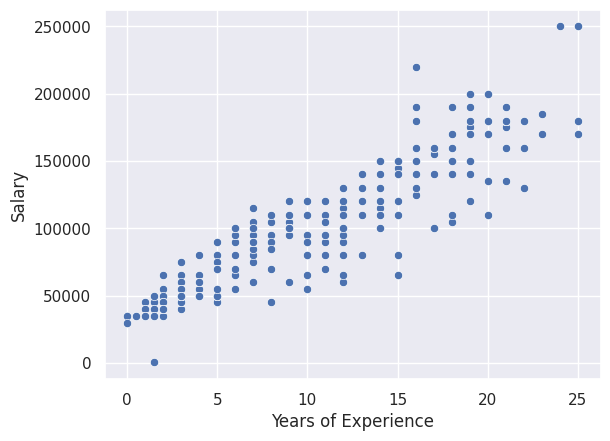

In [5]:
# Visualize the relationship between Years of Experience and Salary

sns.scatterplot(x = X[:,0:1].ravel(), y = y)

plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.show()

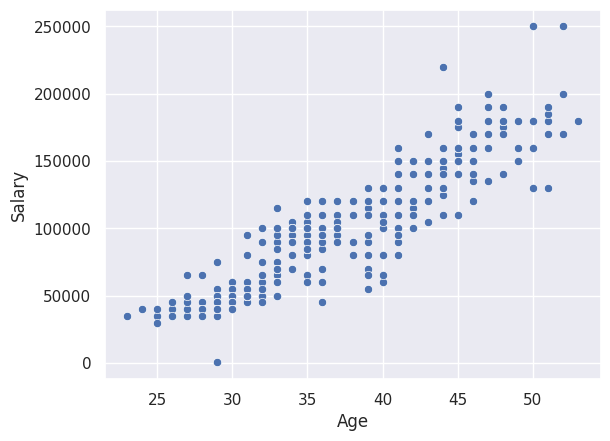

In [6]:
# Visualize the relationship between Age and Salary

sns.scatterplot(x = X[:,1:2].ravel(), y = y)

plt.xlabel('Age')
plt.ylabel('Salary')
plt.show()

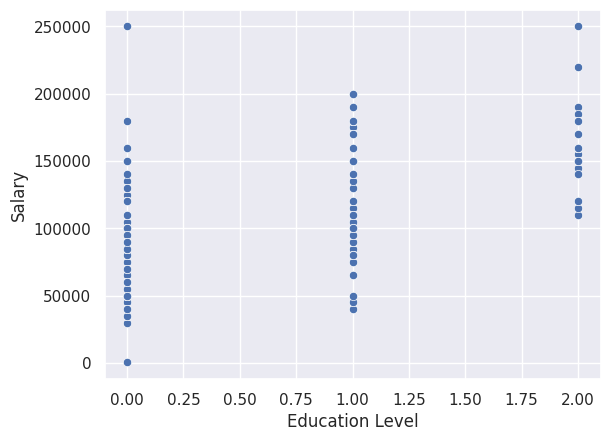

In [7]:
# Visualize the relationship between Education Level and Salary

sns.scatterplot(x = X[:,2:3].ravel(), y = y)

plt.xlabel('Education Level')
plt.ylabel('Salary')
plt.show()

In [8]:
corr = df[['Years of Experience', 'Age', 'Education Level', 'Salary']].copy()

corr_matrix = corr.corr()
print(corr_matrix['Salary'].sort_values(ascending=False))

Salary                 1.000000
Years of Experience    0.930338
Age                    0.922335
Education Level        0.670371
Name: Salary, dtype: float64


Years of Experience is the most strongly linear feature with Salary.

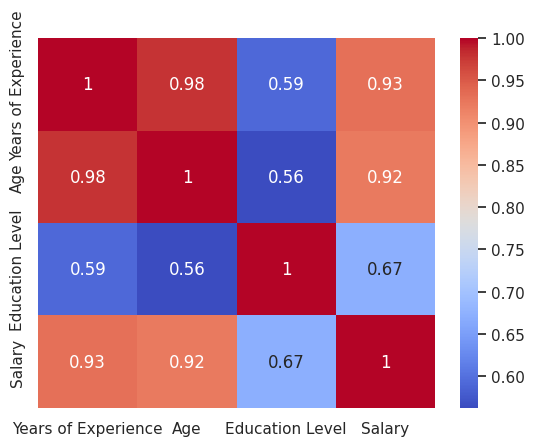

In [9]:
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.show()

**Q2. NumPy দিয়ে Prediction Function লেখো** নিচের data manually define
করো (অন্তত ১০টি row, ৩টি feature):

-   Feature: study_hours, sleep_hours, attendance_pct → Target:
    > exam_score

NumPy ব্যবহার করে:

-   predict(X, w, b) function লেখো যেখানে y_pred = X @ w + b

-   Random weights দিয়ে সব rows এর prediction করো এবং actual values এর সাথে পাশাপাশি print করো


In [10]:
import numpy as np

# 10 students data (3 features) → float version
X = np.array([
    [2.0, 6.0, 70.0],
    [3.5, 5.0, 65.0],
    [1.0, 7.5, 60.0],
    [4.2, 6.1, 80.0],
    [5.0, 5.5, 85.0],
    [6.3, 6.8, 90.0],
    [7.1, 4.5, 95.0],
    [8.0, 6.2, 92.0],
    [9.5, 5.1, 88.0],
    [10.0, 7.3, 96.0]
])

# actual exam scores (float version)
y = np.array([50.0, 55.5, 48.2, 65.7, 70.1, 75.6, 80.3, 85.0, 88.4, 92.8])

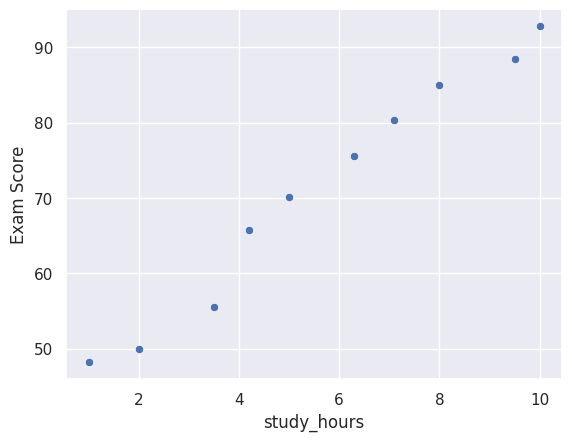

In [11]:
# Visualize the relationship between study_hours and exam score

sns.scatterplot(x = X[:, 0:1].ravel(), y = y)

plt.xlabel('study_hours')
plt.ylabel('Exam Score')
plt.show()

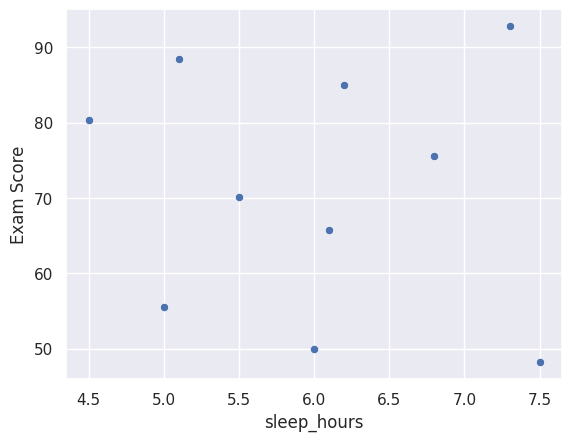

In [12]:
# Visualize the relationship between sleep_hours and exam score

sns.scatterplot(x = X[:, 1:2].ravel(), y = y)

plt.xlabel('sleep_hours')
plt.ylabel('Exam Score')
plt.show()

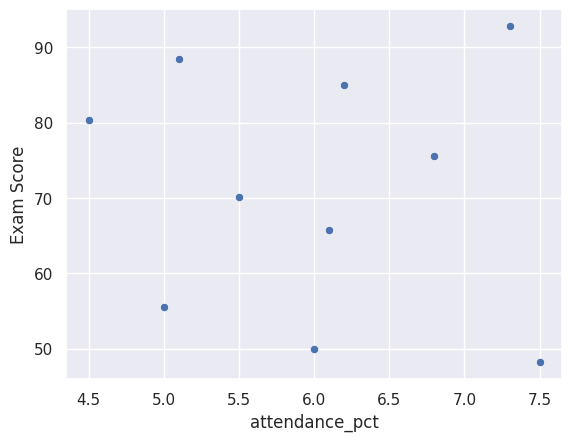

In [13]:
# Visualize the relationship between attendance_pct and exam score

sns.scatterplot(x = X[:, 1:2].ravel(), y = y)

plt.xlabel('attendance_pct')
plt.ylabel('Exam Score')
plt.show()

In [14]:
def make_prediction( X, W, b ) :

  """Calculates the model output : f(x) = wx + b"""

  m = X.shape[0]
  pred_list = np.zeros((m,))

  for i in range( m ) :

    pred_list[i] = np.dot(W, X[i]) + b

  return pred_list


In [15]:
m = X.shape[0]
n = X.shape[1]

W_init = np.random.randn(n)
b_init = 1.0

y_predict = make_prediction( X, W = W_init, b = b_init )
y_predict

array([25.82900466, 22.45541228, 20.47431025, 27.61994428, 29.70314596,
       28.83727014, 32.93866544, 28.18401277, 25.42522107, 26.08865899])

In [16]:
print(f'Actual Values : {y}')
print(f'Predicted Values : {y_predict}')

Actual Values : [50.  55.5 48.2 65.7 70.1 75.6 80.3 85.  88.4 92.8]
Predicted Values : [25.82900466 22.45541228 20.47431025 27.61994428 29.70314596 28.83727014
 32.93866544 28.18401277 25.42522107 26.08865899]


**Q3. Scikit-learn দিয়ে প্রথম Multiple Linear Regression (MLR) Model**
sklearn.datasets.fetch_california_housing() লোড করো।

-   MedInc, AveRooms, HouseAge — শুধু এই ৩টি feature নাও

-   LinearRegression দিয়ে model train করো

-   coef\_ এবং intercept\_ print করো

-   যেকোনো ৫টি sample এর predicted vs actual value দেখাও


In [17]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

data = fetch_california_housing()

df = pd.DataFrame(data.data, columns=data.feature_names)
df['Target'] = data.target

df.head()

X = df[['MedInc', 'AveRooms', 'HouseAge']].values
y = df['Target'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [18]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

weights = model.coef_
bias = model.intercept_

print(weights)
print(bias)

[ 0.4447578  -0.02814968  0.01683623]
0.01729564528337102


In [19]:
y_predict = model.predict(X_test)
n = 5
for i in range(n) :
  print(f'Actual : {round(y_test[i], 4)}')
  print(f'Predicted : {round(y_predict[i], 4)}')

Actual : 0.477
Predicted : 1.0679
Actual : 0.458
Predicted : 1.5063
Actual : 5.0
Predicted : 2.3286
Actual : 2.186
Predicted : 2.6818
Actual : 2.78
Predicted : 2.0918


**Q4. MSE Cost Function implement ও visualize করো** Q2 এর data ব্যবহার
করো।

-   NumPy দিয়ে MSE cost function লেখো: J = (1/2m) \* sum((y_pred - y)^2)

-   w\[0\] কে -10 থেকে +10 এর মধ্যে vary করো, বাকি weights fixed রাখো

-   Cost এর change একটি line plot এ দেখাও এবং minimum কোথায় সেটা mark করো


In [20]:
import numpy as np

# 10 students data (3 features) → float version
X = np.array([
    [2.0, 6.0, 70.0],
    [3.5, 5.0, 65.0],
    [1.0, 7.5, 60.0],
    [4.2, 6.1, 80.0],
    [5.0, 5.5, 85.0],
    [6.3, 6.8, 90.0],
    [7.1, 4.5, 95.0],
    [8.0, 6.2, 92.0],
    [9.5, 5.1, 88.0],
    [10.0, 7.3, 96.0]
])

# actual exam scores (float version)
y = np.array([50.0, 55.5, 48.2, 65.7, 70.1, 75.6, 80.3, 85.0, 88.4, 92.8])


# Prediction

def make_prediction( X, W, b ) :

  """Calculates the model output : f(x) = wx + b"""

  m = X.shape[0]
  pred_list = np.zeros((m,))

  for i in range( m ) :

    pred_list[i] = np.dot(W, X[i]) + b

  return pred_list

In [21]:
# MSE Cost Function

def compute_cost( X, y, W, b ) :

  """Calculates the Mean Squared Error (MSE) to measure model accuracy"""

  m = X.shape[0]
  cost = 0.0

  pred_list = make_prediction(X, W, b)

  error = pred_list - y

  error_squared = error ** 2

  cost = np.sum(error_squared)

  cost = cost / ( 2 * m )

  return cost


In [22]:
W_fixed = np.array([0.0, 2.0, 0.5])  # w[0]=0.0, w[1]=2.0, w[2]=0.5
b_fixed = 1.0

w0_values = np.linspace(-10, 10, 200)  # -10 to 10, 200 values
costs = []

for w0 in w0_values:
    w_temp = W_fixed.copy()
    w_temp[0] = w0
    costs.append(compute_cost(X, y, w_temp, b_fixed))

costs = np.array(costs)
costs

array([3.47170650e+03, 3.41868473e+03, 3.36607127e+03, 3.31386612e+03,
       3.26206928e+03, 3.21068076e+03, 3.15970055e+03, 3.10912866e+03,
       3.05896508e+03, 3.00920981e+03, 2.95986285e+03, 2.91092421e+03,
       2.86239387e+03, 2.81427186e+03, 2.76655815e+03, 2.71925276e+03,
       2.67235568e+03, 2.62586691e+03, 2.57978646e+03, 2.53411432e+03,
       2.48885049e+03, 2.44399498e+03, 2.39954777e+03, 2.35550889e+03,
       2.31187831e+03, 2.26865605e+03, 2.22584210e+03, 2.18343646e+03,
       2.14143914e+03, 2.09985012e+03, 2.05866943e+03, 2.01789704e+03,
       1.97753297e+03, 1.93757721e+03, 1.89802976e+03, 1.85889063e+03,
       1.82015981e+03, 1.78183730e+03, 1.74392310e+03, 1.70641722e+03,
       1.66931965e+03, 1.63263039e+03, 1.59634945e+03, 1.56047682e+03,
       1.52501250e+03, 1.48995650e+03, 1.45530881e+03, 1.42106943e+03,
       1.38723836e+03, 1.35381561e+03, 1.32080117e+03, 1.28819504e+03,
       1.25599723e+03, 1.22420773e+03, 1.19282654e+03, 1.16185366e+03,
      

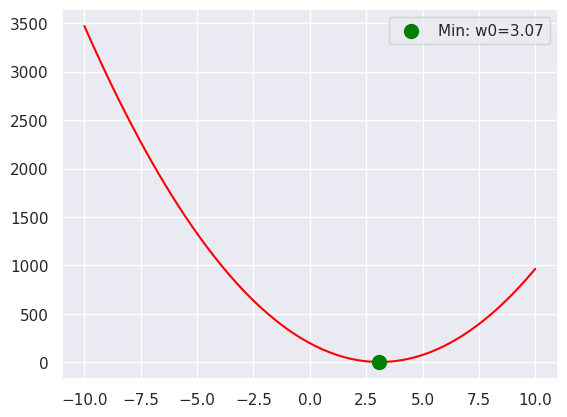

In [23]:
min_idx = np.argmin(costs)
best_w0 = w0_values[min_idx]
min_cost = costs[min_idx]

plt.plot(w0_values, costs, color = 'red')
plt.scatter(best_w0, min_cost, color = 'green', s = 100, zorder = 5, label = f"Min: w0={best_w0:.2f}")
plt.legend()
plt.show()

**Q5. Gradient Descent from Scratch** [<u>Advertising
dataset</u>](https://raw.githubusercontent.com/selva86/datasets/master/Advertising.csv)
(TV, Radio, Newspaper → Sales)।

-   Gradient বের করার formula implement করো: dw = (1/m) \* X.T @
    > (y_pred - y)

-   Learning rate 0.01 দিয়ে ১০০০ iteration চালাও

-   প্রতি ১০০ iteration এ cost print করো

-   Cost vs Iteration curve plot করো এবং কোথায় converge করেছে সেটা দেখাও


In [24]:
from sklearn.preprocessing import StandardScaler
from io import StringIO

data = """
TV,radio,newspaper,sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9
6,8.7,48.9,75,7.2
7,57.5,32.8,23.5,11.8
8,120.2,19.6,11.6,13.2
9,8.6,2.1,1,4.8
10,199.8,2.6,21.2,10.6
11,66.1,5.8,24.2,8.6
12,214.7,24,4,17.4
13,23.8,35.1,65.9,9.2
14,97.5,7.6,7.2,9.7
15,204.1,32.9,46,19
16,195.4,47.7,52.9,22.4
17,67.8,36.6,114,12.5
18,281.4,39.6,55.8,24.4
19,69.2,20.5,18.3,11.3
20,147.3,23.9,19.1,14.6
21,218.4,27.7,53.4,18
22,237.4,5.1,23.5,12.5
23,13.2,15.9,49.6,5.6
24,228.3,16.9,26.2,15.5
25,62.3,12.6,18.3,9.7
26,262.9,3.5,19.5,12
27,142.9,29.3,12.6,15
28,240.1,16.7,22.9,15.9
29,248.8,27.1,22.9,18.9
30,70.6,16,40.8,10.5
31,292.9,28.3,43.2,21.4
32,112.9,17.4,38.6,11.9
33,97.2,1.5,30,9.6
34,265.6,20,0.3,17.4
35,95.7,1.4,7.4,9.5
36,290.7,4.1,8.5,12.8
37,266.9,43.8,5,25.4
38,74.7,49.4,45.7,14.7
39,43.1,26.7,35.1,10.1
40,228,37.7,32,21.5
41,202.5,22.3,31.6,16.6
42,177,33.4,38.7,17.1
43,293.6,27.7,1.8,20.7
44,206.9,8.4,26.4,12.9
45,25.1,25.7,43.3,8.5
46,175.1,22.5,31.5,14.9
47,89.7,9.9,35.7,10.6
48,239.9,41.5,18.5,23.2
49,227.2,15.8,49.9,14.8
50,66.9,11.7,36.8,9.7
51,199.8,3.1,34.6,11.4
52,100.4,9.6,3.6,10.7
53,216.4,41.7,39.6,22.6
54,182.6,46.2,58.7,21.2
55,262.7,28.8,15.9,20.2
56,198.9,49.4,60,23.7
57,7.3,28.1,41.4,5.5
58,136.2,19.2,16.6,13.2
59,210.8,49.6,37.7,23.8
60,210.7,29.5,9.3,18.4
61,53.5,2,21.4,8.1
62,261.3,42.7,54.7,24.2
63,239.3,15.5,27.3,15.7
64,102.7,29.6,8.4,14
65,131.1,42.8,28.9,18
66,69,9.3,0.9,9.3
67,31.5,24.6,2.2,9.5
68,139.3,14.5,10.2,13.4
69,237.4,27.5,11,18.9
70,216.8,43.9,27.2,22.3
71,199.1,30.6,38.7,18.3
72,109.8,14.3,31.7,12.4
73,26.8,33,19.3,8.8
74,129.4,5.7,31.3,11
75,213.4,24.6,13.1,17
76,16.9,43.7,89.4,8.7
77,27.5,1.6,20.7,6.9
78,120.5,28.5,14.2,14.2
79,5.4,29.9,9.4,5.3
80,116,7.7,23.1,11
81,76.4,26.7,22.3,11.8
82,239.8,4.1,36.9,12.3
83,75.3,20.3,32.5,11.3
84,68.4,44.5,35.6,13.6
85,213.5,43,33.8,21.7
86,193.2,18.4,65.7,15.2
87,76.3,27.5,16,12
88,110.7,40.6,63.2,16
89,88.3,25.5,73.4,12.9
90,109.8,47.8,51.4,16.7
91,134.3,4.9,9.3,11.2
92,28.6,1.5,33,7.3
93,217.7,33.5,59,19.4
94,250.9,36.5,72.3,22.2
95,107.4,14,10.9,11.5
96,163.3,31.6,52.9,16.9
97,197.6,3.5,5.9,11.7
98,184.9,21,22,15.5
99,289.7,42.3,51.2,25.4
100,135.2,41.7,45.9,17.2
101,222.4,4.3,49.8,11.7
102,296.4,36.3,100.9,23.8
103,280.2,10.1,21.4,14.8
104,187.9,17.2,17.9,14.7
105,238.2,34.3,5.3,20.7
106,137.9,46.4,59,19.2
107,25,11,29.7,7.2
108,90.4,0.3,23.2,8.7
109,13.1,0.4,25.6,5.3
110,255.4,26.9,5.5,19.8
111,225.8,8.2,56.5,13.4
112,241.7,38,23.2,21.8
113,175.7,15.4,2.4,14.1
114,209.6,20.6,10.7,15.9
115,78.2,46.8,34.5,14.6
116,75.1,35,52.7,12.6
117,139.2,14.3,25.6,12.2
118,76.4,0.8,14.8,9.4
119,125.7,36.9,79.2,15.9
120,19.4,16,22.3,6.6
121,141.3,26.8,46.2,15.5
122,18.8,21.7,50.4,7
123,224,2.4,15.6,11.6
124,123.1,34.6,12.4,15.2
125,229.5,32.3,74.2,19.7
126,87.2,11.8,25.9,10.6
127,7.8,38.9,50.6,6.6
128,80.2,0,9.2,8.8
129,220.3,49,3.2,24.7
130,59.6,12,43.1,9.7
131,0.7,39.6,8.7,1.6
132,265.2,2.9,43,12.7
133,8.4,27.2,2.1,5.7
134,219.8,33.5,45.1,19.6
135,36.9,38.6,65.6,10.8
136,48.3,47,8.5,11.6
137,25.6,39,9.3,9.5
138,273.7,28.9,59.7,20.8
139,43,25.9,20.5,9.6
140,184.9,43.9,1.7,20.7
141,73.4,17,12.9,10.9
142,193.7,35.4,75.6,19.2
143,220.5,33.2,37.9,20.1
144,104.6,5.7,34.4,10.4
145,96.2,14.8,38.9,11.4
146,140.3,1.9,9,10.3
147,240.1,7.3,8.7,13.2
148,243.2,49,44.3,25.4
149,38,40.3,11.9,10.9
150,44.7,25.8,20.6,10.1
151,280.7,13.9,37,16.1
152,121,8.4,48.7,11.6
153,197.6,23.3,14.2,16.6
154,171.3,39.7,37.7,19
155,187.8,21.1,9.5,15.6
156,4.1,11.6,5.7,3.2
157,93.9,43.5,50.5,15.3
158,149.8,1.3,24.3,10.1
159,11.7,36.9,45.2,7.3
160,131.7,18.4,34.6,12.9
161,172.5,18.1,30.7,14.4
162,85.7,35.8,49.3,13.3
163,188.4,18.1,25.6,14.9
164,163.5,36.8,7.4,18
165,117.2,14.7,5.4,11.9
166,234.5,3.4,84.8,11.9
167,17.9,37.6,21.6,8
168,206.8,5.2,19.4,12.2
169,215.4,23.6,57.6,17.1
170,284.3,10.6,6.4,15
171,50,11.6,18.4,8.4
172,164.5,20.9,47.4,14.5
173,19.6,20.1,17,7.6
174,168.4,7.1,12.8,11.7
175,222.4,3.4,13.1,11.5
176,276.9,48.9,41.8,27
177,248.4,30.2,20.3,20.2
178,170.2,7.8,35.2,11.7
179,276.7,2.3,23.7,11.8
180,165.6,10,17.6,12.6
181,156.6,2.6,8.3,10.5
182,218.5,5.4,27.4,12.2
183,56.2,5.7,29.7,8.7
184,287.6,43,71.8,26.2
185,253.8,21.3,30,17.6
186,205,45.1,19.6,22.6
187,139.5,2.1,26.6,10.3
188,191.1,28.7,18.2,17.3
189,286,13.9,3.7,15.9
190,18.7,12.1,23.4,6.7
191,39.5,41.1,5.8,10.8
192,75.5,10.8,6,9.9
193,17.2,4.1,31.6,5.9
194,166.8,42,3.6,19.6
195,149.7,35.6,6,17.3
196,38.2,3.7,13.8,7.6
197,94.2,4.9,8.1,9.7
198,177,9.3,6.4,12.8
199,283.6,42,66.2,25.5
200,232.1,8.6,8.7,13.4
"""

df = pd.read_csv(StringIO(data))
# df.info()

X = df[['TV', 'radio', 'newspaper']].values
y = df['sales'].values

scaler = StandardScaler()

X = scaler.fit_transform(X)

In [25]:
def make_prediction( X, W, b ) :

  """Calculates the model output : f(x) = wx + b"""

  m = X.shape[0]
  pred_list = np.zeros((m,))

  for i in range(m) :

    pred_list[i] = np.dot(W, X[i]) + b

  return pred_list


In [26]:
m = X.shape[0]
n = X.shape[1]

W_init = np.ones((n,))
b_init = 1.0

make_prediction(X, W_init, b_init)

array([ 4.73032021e+00,  1.55501034e+00,  2.79585697e+00,  3.55630968e+00,
        1.83437042e+00,  3.16155553e+00,  2.73619440e-01, -4.33329908e-01,
       -3.40606898e+00, -2.09845560e-01, -1.41687327e+00,  6.17396913e-01,
        1.98716175e+00, -1.71121773e+00,  3.02791787e+00,  4.24329724e+00,
        4.81635994e+00,  4.83406014e+00, -6.59666313e-01,  5.18703388e-01,
        3.18441012e+00,  5.03887112e-01, -1.83384075e-01,  1.31869143e+00,
       -1.27367290e+00,  5.09482541e-01,  5.32745563e-01,  1.29106889e+00,
        2.09490275e+00,  8.85410993e-02,  3.62532715e+00,  5.75736019e-01,
       -1.07708917e+00,  7.71338035e-01, -2.14167582e+00,  3.68263927e-01,
        2.60992823e+00,  2.61725910e+00,  2.27547721e-01,  2.98666294e+00,
        1.63062701e+00,  2.40920402e+00,  1.68726974e+00,  5.04062351e-01,
        3.27301234e-01,  1.31958209e+00, -3.35086504e-01,  2.76077783e+00,
        2.32252493e+00, -4.29141911e-01,  4.40742522e-01, -1.70802220e+00,
        3.47114719e+00,  

In [27]:
def compute_cost(X, y, W, b) :

  """Calculates the Mean Squared Error (MSE) to measure model accuracy"""

  m = X.shape[0]
  cost = 0.0

  pred_list = make_prediction(X, W, b)

  error = pred_list - y

  error_squared = error ** 2

  cost = np.sum(error_squared)

  cost = cost / ( 2 * m )

  return cost


In [28]:
W_init = np.ones((n, ))
b_init = 1.0

compute_cost(X, y, W_init, b_init)

np.float64(92.04312970196048)

In [29]:
def calculate_gradient(X, y, W, b):

    m = X.shape[0]

    y_pred = X @ W + b

    error = y_pred - y

    dj_dw = (1 / m) * (X.T @ error)

    dj_db = (1 / m) * np.sum(error)

    return dj_dw, dj_db

In [30]:
W_init = np.ones((n, ))
b_init = 1.0

calculate_gradient(X, y, W_init, b_init)

# (array([-2.95954958, -1.58997838,  0.22259295]),
#  np.float64(-13.022499999999994))

(array([-2.95954958, -1.58997838,  0.22259295]), np.float64(-13.0225))

In [31]:
def gradient_descent( X, y, w_input, b_input, max_iter, alpha ) :

  """Automates the tuning of w and b to minimize cost"""

  w = w_input
  b = b_input

  cost_memo = []
  iteration = []

  for i in range(max_iter) :

    dj_dw, dj_db = calculate_gradient( X, y, w, b )

    w = w - alpha * dj_dw
    b = b - alpha * dj_db

    cost = compute_cost( X, y, w, b )
    cost_memo.append(cost)
    iteration.append(i)

    if i % 100 == 0 :
      print(f'Iteration : {i}, Cost : {cost:0.04f}')

  return w, b, cost_memo, iteration


In [32]:
n = X.shape[1]

W_init = np.zeros((n,))
b_init = 0.0

w_final, b_final, cost_memo, iter_list = gradient_descent(X, y, w_input = W_init, b_input = b_init, max_iter = 1001, alpha = 0.01)

Iteration : 0, Cost : 109.6334
Iteration : 100, Cost : 15.7476
Iteration : 200, Cost : 3.3457
Iteration : 300, Cost : 1.6663
Iteration : 400, Cost : 1.4324
Iteration : 500, Cost : 1.3985
Iteration : 600, Cost : 1.3932
Iteration : 700, Cost : 1.3923
Iteration : 800, Cost : 1.3921
Iteration : 900, Cost : 1.3921
Iteration : 1000, Cost : 1.3921


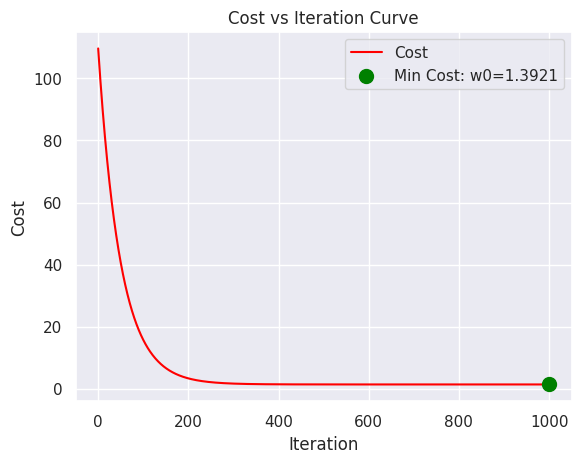

In [33]:
min_idx = np.argmin(cost_memo)
min_cost = cost_memo[min_idx]

plt.plot(iter_list, cost_memo, color='red', label='Cost')

plt.scatter(iter_list[min_idx], min_cost, color = 'green', s = 100, zorder = 5, label = f"Min Cost: w0={min_cost:.4f}")

plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Cost vs Iteration Curve")

plt.legend()
plt.show()

**Q6. LinearRegression vs SGDRegressor তুলনা** Energy Efficiency dataset
([<u>UCI</u>](https://archive.ics.uci.edu/dataset/242/energy+efficiency))
থেকে heating load predict করো।

-   LinearRegression এবং SGDRegressor দুটোই একই data তে train করো

-   দুটোর learned weights ও MSE পাশাপাশি একটি table এ দেখাও

-   ২-৩ লাইনে লেখো কেন SGDRegressor এর weights exact match করে না

*Covers: Scikit-learn SGDRegressor, why results differ*


In [34]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import SGDRegressor

In [35]:
pip install ucimlrepo

In [36]:
from ucimlrepo import fetch_ucirepo
# fetch dataset
energy_efficiency = fetch_ucirepo(id=242)

# data (as pandas dataframes)
X = energy_efficiency.data.features
y = energy_efficiency.data.targets

X = X.values
y = energy_efficiency.data.targets['Y1'].values

In [37]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.2, random_state = 42 )

In [38]:
from sklearn.metrics import mean_squared_error

model1 = LinearRegression()

model1.fit(X_train, y_train)

lr_weights = model1.coef_
lr_bias = model1.intercept_

lr_pred = model1.predict(X_test)
lr_mse = mean_squared_error(y_test, lr_pred)

In [39]:
model2 = SGDRegressor(penalty = None, max_iter = 1000, learning_rate = 'constant')

model2.fit(X_train, y_train)

sgd_weights = model2.coef_
sgd_bias = model2.intercept_

sgd_pred = model2.predict(X_test)
sgd_mse = mean_squared_error(y_test, sgd_pred)

In [40]:
table1 = pd.DataFrame({
    "LinearRegression" : lr_weights,
    "SGDRegressor" : sgd_weights
})
print(f'Learned Weights : \n{table1}')

table2 = pd.DataFrame({
    "Model": ["LinearRegression", "SGDRegressor"],
    "MSE": [lr_mse, sgd_mse]
})

print(f'MSE : \n{table2}')

Learned Weights : 
   LinearRegression  SGDRegressor
0        -61.873354 -6.387171e+09
1         -0.060105  2.464761e+12
2          0.037553 -5.766169e+12
3         -0.048829  4.115465e+12
4          4.123669 -2.263284e+11
5         -0.032439 -1.083349e+12
6         20.143192 -9.046638e+10
7          0.211103  6.706637e+11
MSE : 
              Model           MSE
0  LinearRegression  9.153188e+00
1      SGDRegressor  4.999088e+29


LinearRegression computes the optimal weights using an exact closed-form solution.
SGDRegressor updates the weights iteratively using Gradient Descent, so it finds an approximate solution rather than the exact one.
Due to the learning rate, random updates, and limited iterations, its weights may not exactly match those of LinearRegression

### **(Optional)**



**Q7. Learning Rate এর Effect পরীক্ষা করো** Q5 এর Advertising dataset এবং
তোমার নিজের Gradient Descent implementation ব্যবহার করো।

-   চারটি আলাদা learning rate চালাও: 0.0001, 0.01, 0.1, 1.0

-   সব ৪টির cost curve একই plot এ আঁকো (আলাদা color এ)

-   কোন rate এ model diverge করে, কোনটিতে slow converge হয়, কোনটি
optimal — সেটা সংখ্যা দিয়ে explain করো


In [41]:
from sklearn.preprocessing import StandardScaler
from io import StringIO

data = """
TV,radio,newspaper,sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9
6,8.7,48.9,75,7.2
7,57.5,32.8,23.5,11.8
8,120.2,19.6,11.6,13.2
9,8.6,2.1,1,4.8
10,199.8,2.6,21.2,10.6
11,66.1,5.8,24.2,8.6
12,214.7,24,4,17.4
13,23.8,35.1,65.9,9.2
14,97.5,7.6,7.2,9.7
15,204.1,32.9,46,19
16,195.4,47.7,52.9,22.4
17,67.8,36.6,114,12.5
18,281.4,39.6,55.8,24.4
19,69.2,20.5,18.3,11.3
20,147.3,23.9,19.1,14.6
21,218.4,27.7,53.4,18
22,237.4,5.1,23.5,12.5
23,13.2,15.9,49.6,5.6
24,228.3,16.9,26.2,15.5
25,62.3,12.6,18.3,9.7
26,262.9,3.5,19.5,12
27,142.9,29.3,12.6,15
28,240.1,16.7,22.9,15.9
29,248.8,27.1,22.9,18.9
30,70.6,16,40.8,10.5
31,292.9,28.3,43.2,21.4
32,112.9,17.4,38.6,11.9
33,97.2,1.5,30,9.6
34,265.6,20,0.3,17.4
35,95.7,1.4,7.4,9.5
36,290.7,4.1,8.5,12.8
37,266.9,43.8,5,25.4
38,74.7,49.4,45.7,14.7
39,43.1,26.7,35.1,10.1
40,228,37.7,32,21.5
41,202.5,22.3,31.6,16.6
42,177,33.4,38.7,17.1
43,293.6,27.7,1.8,20.7
44,206.9,8.4,26.4,12.9
45,25.1,25.7,43.3,8.5
46,175.1,22.5,31.5,14.9
47,89.7,9.9,35.7,10.6
48,239.9,41.5,18.5,23.2
49,227.2,15.8,49.9,14.8
50,66.9,11.7,36.8,9.7
51,199.8,3.1,34.6,11.4
52,100.4,9.6,3.6,10.7
53,216.4,41.7,39.6,22.6
54,182.6,46.2,58.7,21.2
55,262.7,28.8,15.9,20.2
56,198.9,49.4,60,23.7
57,7.3,28.1,41.4,5.5
58,136.2,19.2,16.6,13.2
59,210.8,49.6,37.7,23.8
60,210.7,29.5,9.3,18.4
61,53.5,2,21.4,8.1
62,261.3,42.7,54.7,24.2
63,239.3,15.5,27.3,15.7
64,102.7,29.6,8.4,14
65,131.1,42.8,28.9,18
66,69,9.3,0.9,9.3
67,31.5,24.6,2.2,9.5
68,139.3,14.5,10.2,13.4
69,237.4,27.5,11,18.9
70,216.8,43.9,27.2,22.3
71,199.1,30.6,38.7,18.3
72,109.8,14.3,31.7,12.4
73,26.8,33,19.3,8.8
74,129.4,5.7,31.3,11
75,213.4,24.6,13.1,17
76,16.9,43.7,89.4,8.7
77,27.5,1.6,20.7,6.9
78,120.5,28.5,14.2,14.2
79,5.4,29.9,9.4,5.3
80,116,7.7,23.1,11
81,76.4,26.7,22.3,11.8
82,239.8,4.1,36.9,12.3
83,75.3,20.3,32.5,11.3
84,68.4,44.5,35.6,13.6
85,213.5,43,33.8,21.7
86,193.2,18.4,65.7,15.2
87,76.3,27.5,16,12
88,110.7,40.6,63.2,16
89,88.3,25.5,73.4,12.9
90,109.8,47.8,51.4,16.7
91,134.3,4.9,9.3,11.2
92,28.6,1.5,33,7.3
93,217.7,33.5,59,19.4
94,250.9,36.5,72.3,22.2
95,107.4,14,10.9,11.5
96,163.3,31.6,52.9,16.9
97,197.6,3.5,5.9,11.7
98,184.9,21,22,15.5
99,289.7,42.3,51.2,25.4
100,135.2,41.7,45.9,17.2
101,222.4,4.3,49.8,11.7
102,296.4,36.3,100.9,23.8
103,280.2,10.1,21.4,14.8
104,187.9,17.2,17.9,14.7
105,238.2,34.3,5.3,20.7
106,137.9,46.4,59,19.2
107,25,11,29.7,7.2
108,90.4,0.3,23.2,8.7
109,13.1,0.4,25.6,5.3
110,255.4,26.9,5.5,19.8
111,225.8,8.2,56.5,13.4
112,241.7,38,23.2,21.8
113,175.7,15.4,2.4,14.1
114,209.6,20.6,10.7,15.9
115,78.2,46.8,34.5,14.6
116,75.1,35,52.7,12.6
117,139.2,14.3,25.6,12.2
118,76.4,0.8,14.8,9.4
119,125.7,36.9,79.2,15.9
120,19.4,16,22.3,6.6
121,141.3,26.8,46.2,15.5
122,18.8,21.7,50.4,7
123,224,2.4,15.6,11.6
124,123.1,34.6,12.4,15.2
125,229.5,32.3,74.2,19.7
126,87.2,11.8,25.9,10.6
127,7.8,38.9,50.6,6.6
128,80.2,0,9.2,8.8
129,220.3,49,3.2,24.7
130,59.6,12,43.1,9.7
131,0.7,39.6,8.7,1.6
132,265.2,2.9,43,12.7
133,8.4,27.2,2.1,5.7
134,219.8,33.5,45.1,19.6
135,36.9,38.6,65.6,10.8
136,48.3,47,8.5,11.6
137,25.6,39,9.3,9.5
138,273.7,28.9,59.7,20.8
139,43,25.9,20.5,9.6
140,184.9,43.9,1.7,20.7
141,73.4,17,12.9,10.9
142,193.7,35.4,75.6,19.2
143,220.5,33.2,37.9,20.1
144,104.6,5.7,34.4,10.4
145,96.2,14.8,38.9,11.4
146,140.3,1.9,9,10.3
147,240.1,7.3,8.7,13.2
148,243.2,49,44.3,25.4
149,38,40.3,11.9,10.9
150,44.7,25.8,20.6,10.1
151,280.7,13.9,37,16.1
152,121,8.4,48.7,11.6
153,197.6,23.3,14.2,16.6
154,171.3,39.7,37.7,19
155,187.8,21.1,9.5,15.6
156,4.1,11.6,5.7,3.2
157,93.9,43.5,50.5,15.3
158,149.8,1.3,24.3,10.1
159,11.7,36.9,45.2,7.3
160,131.7,18.4,34.6,12.9
161,172.5,18.1,30.7,14.4
162,85.7,35.8,49.3,13.3
163,188.4,18.1,25.6,14.9
164,163.5,36.8,7.4,18
165,117.2,14.7,5.4,11.9
166,234.5,3.4,84.8,11.9
167,17.9,37.6,21.6,8
168,206.8,5.2,19.4,12.2
169,215.4,23.6,57.6,17.1
170,284.3,10.6,6.4,15
171,50,11.6,18.4,8.4
172,164.5,20.9,47.4,14.5
173,19.6,20.1,17,7.6
174,168.4,7.1,12.8,11.7
175,222.4,3.4,13.1,11.5
176,276.9,48.9,41.8,27
177,248.4,30.2,20.3,20.2
178,170.2,7.8,35.2,11.7
179,276.7,2.3,23.7,11.8
180,165.6,10,17.6,12.6
181,156.6,2.6,8.3,10.5
182,218.5,5.4,27.4,12.2
183,56.2,5.7,29.7,8.7
184,287.6,43,71.8,26.2
185,253.8,21.3,30,17.6
186,205,45.1,19.6,22.6
187,139.5,2.1,26.6,10.3
188,191.1,28.7,18.2,17.3
189,286,13.9,3.7,15.9
190,18.7,12.1,23.4,6.7
191,39.5,41.1,5.8,10.8
192,75.5,10.8,6,9.9
193,17.2,4.1,31.6,5.9
194,166.8,42,3.6,19.6
195,149.7,35.6,6,17.3
196,38.2,3.7,13.8,7.6
197,94.2,4.9,8.1,9.7
198,177,9.3,6.4,12.8
199,283.6,42,66.2,25.5
200,232.1,8.6,8.7,13.4
"""

df = pd.read_csv(StringIO(data))
# df.info()

X = df[['TV', 'radio', 'newspaper']].values
y = df['sales'].values

ss = StandardScaler()

X = ss.fit_transform(X)

def make_prediction( X, W, b ) :

  """Calculates the model output : f(x) = wx + b"""

  m = X.shape[0]
  pred_list = np.zeros((m,))

  for i in range(m) :

    pred_list[i] = np.dot(W, X[i]) + b

  return pred_list

def compute_cost(X, y, W, b) :

  """Calculates the Mean Squared Error (MSE) to measure model accuracy"""

  m = X.shape[0]
  cost = 0.0

  pred_list = make_prediction(X, W, b)

  error = pred_list - y

  error_squared = error ** 2

  cost = np.sum(error_squared)

  cost = cost / ( 2 * m )

  return cost

def calculate_gradient(X, y, W, b):

    m = X.shape[0]

    y_pred = X @ W + b

    error = y_pred - y

    dj_dw = (1 / m) * (X.T @ error)

    dj_db = (1 / m) * np.sum(error)

    return dj_dw, dj_db

def gradient_descent( X, y, w_input, b_input, max_iter, alpha ) :

  """Automates the tuning of w and b to minimize cost"""

  w = w_input
  b = b_input

  cost_memo = []
  iteration = []

  for i in range(max_iter) :

    dj_dw, dj_db = calculate_gradient( X, y, w, b )

    w = w - alpha * dj_dw
    b = b - alpha * dj_db

    cost = compute_cost( X, y, w, b )
    cost_memo.append(cost)
    iteration.append(i)

    if i % 100 == 0 :
      print(f'Iteration : {i}, dj_dw : {dj_dw}, dj_db : {dj_db}, Cost : {cost:0.04f}')

  return w, b, cost_memo, iteration


In [42]:
W_init = np.ones((n,))
b_init = 0.0

W_final, b_final, cost_memo, iteration = gradient_descent( X, y, W_init, b_init, max_iter = 1001, alpha = 0.0001 )

Iteration : 0, dj_dw : [-2.95954958 -1.58997838  0.22259295], dj_db : -14.0225, Cost : 105.5448
Iteration : 100, dj_dw : [-2.92936435 -1.57334426  0.22761108], dj_db : -13.882966851799747, Cost : 103.4862
Iteration : 200, dj_dw : [-2.89949129 -1.5569095   0.23250408], dj_db : -13.744822150698566, Cost : 101.4683
Iteration : 300, dj_dw : [-2.86992712 -1.54067151  0.23727408], dj_db : -13.608052080729617, Cost : 99.4904
Iteration : 400, dj_dw : [-2.84066859 -1.52462774  0.24192316], dj_db : -13.472642963404088, Cost : 97.5517
Iteration : 500, dj_dw : [-2.81171249 -1.50877566  0.24645337], dj_db : -13.338581256343168, Cost : 95.6514
Iteration : 600, dj_dw : [-2.78305564 -1.49311279  0.25086674], dj_db : -13.205853551923669, Cost : 93.7888
Iteration : 700, dj_dw : [-2.75469488 -1.47763667  0.25516526], dj_db : -13.074446575937118, Cost : 91.9631
Iteration : 800, dj_dw : [-2.72662712 -1.46234488  0.2593509 ], dj_db : -12.944347186262203, Cost : 90.1735
Iteration : 900, dj_dw : [-2.69884927 

In [43]:
W_init = np.ones((n,))
b_init = 0.0

W_final, b_final, cost_memo, iteration = gradient_descent( X, y, W_init, b_init, max_iter = 1001, alpha = 0.01 )

Iteration : 0, dj_dw : [-2.95954958 -1.58997838  0.22259295], dj_db : -14.0225, Cost : 103.4964
Iteration : 100, dj_dw : [-1.06332101 -0.5993701   0.35116882], dj_db : -5.1326885055038565, Cost : 15.2057
Iteration : 200, dj_dw : [-0.38637848 -0.26242696  0.2356595 ], dj_db : -1.8787299906957753, Cost : 3.2900
Iteration : 300, dj_dw : [-0.14156188 -0.12715221  0.13370975], dj_db : -0.6876759371146084, Cost : 1.6598
Iteration : 400, dj_dw : [-0.05218181 -0.06498322  0.07158831], dj_db : -0.2517116332993241, Cost : 1.4316
Iteration : 500, dj_dw : [-0.01932422 -0.03398608  0.03749667], dj_db : -0.09213459846225698, Cost : 1.3984
Iteration : 600, dj_dw : [-0.00718326 -0.01791722  0.01949096], dj_db : -0.03372424278740727, Cost : 1.3932
Iteration : 700, dj_dw : [-0.00267927 -0.00945988  0.01011408], dj_db : -0.012344163545142388, Cost : 1.3923
Iteration : 800, dj_dw : [-0.0010028  -0.00498994  0.00525132], dj_db : -0.004518363083496473, Cost : 1.3921
Iteration : 900, dj_dw : [-0.00037681 -0.

In [44]:
W_init = np.ones((n,))
b_init = 0.0

W_final, b_final, cost_memo, iteration = gradient_descent( X, y, W_init, b_init, max_iter = 1001, alpha = 0.1 )

Iteration : 0, dj_dw : [-2.95954958 -1.58997838  0.22259295], dj_db : -14.0225, Cost : 85.8097
Iteration : 100, dj_dw : [-9.03940983e-05 -1.13820042e-03  1.16359865e-03], dj_db : -0.00037245721590112524, Cost : 1.3921
Iteration : 200, dj_dw : [-1.04136716e-08 -1.44897074e-06  1.45099457e-06], dj_db : -9.892985808335198e-09, Cost : 1.3921
Iteration : 300, dj_dw : [-9.81364323e-12 -1.82566358e-09  1.82722072e-09], dj_db : -2.645705876602733e-13, Cost : 1.3921
Iteration : 400, dj_dw : [-1.20614629e-14 -2.29997354e-12  2.30163222e-12], dj_db : -8.695266728864227e-15, Cost : 1.3921
Iteration : 500, dj_dw : [-1.95399252e-15 -2.77111667e-15  3.00648395e-15], dj_db : -6.8567374000849666e-15, Cost : 1.3921
Iteration : 600, dj_dw : [-1.82076576e-15 -1.97175609e-15 -4.44089210e-18], dj_db : -7.105427357601002e-15, Cost : 1.3921
Iteration : 700, dj_dw : [-1.82076576e-15 -1.97175609e-15 -4.44089210e-18], dj_db : -7.105427357601002e-15, Cost : 1.3921
Iteration : 800, dj_dw : [-1.82076576e-15 -1.9717

In [45]:
W_init = np.ones((n,))
b_init = 0.0

W_final, b_final, cost_memo, iteration = gradient_descent( X, y, W_init, b_init, max_iter = 1001, alpha = 1.0 )

Iteration : 0, dj_dw : [-2.95954958 -1.58997838  0.22259295], dj_db : -14.0225, Cost : 1.6774
Iteration : 100, dj_dw : [-1.24344979e-16  1.59872116e-16  2.66453526e-17], dj_db : 1.2434497875801754e-16, Cost : 1.3921
Iteration : 200, dj_dw : [-1.24344979e-16  1.59872116e-16  2.66453526e-17], dj_db : 1.2434497875801754e-16, Cost : 1.3921
Iteration : 300, dj_dw : [-1.24344979e-16  1.59872116e-16  2.66453526e-17], dj_db : 1.2434497875801754e-16, Cost : 1.3921
Iteration : 400, dj_dw : [-1.24344979e-16  1.59872116e-16  2.66453526e-17], dj_db : 1.2434497875801754e-16, Cost : 1.3921
Iteration : 500, dj_dw : [-1.24344979e-16  1.59872116e-16  2.66453526e-17], dj_db : 1.2434497875801754e-16, Cost : 1.3921
Iteration : 600, dj_dw : [-1.24344979e-16  1.59872116e-16  2.66453526e-17], dj_db : 1.2434497875801754e-16, Cost : 1.3921
Iteration : 700, dj_dw : [-1.24344979e-16  1.59872116e-16  2.66453526e-17], dj_db : 1.2434497875801754e-16, Cost : 1.3921
Iteration : 800, dj_dw : [-1.24344979e-16  1.5987211

In [46]:
learning_rates = [0.0001, 0.01, 0.1, 1.0]

cost_history = {}

for i in learning_rates :

  W_init = np.zeros(X.shape[1])
  b_init = 0

  W_final, b_final, cost_memo, iteration = gradient_descent( X, y, W_init, b_init, max_iter = 1001, alpha = i )

  cost_history[i] =  cost_memo

Iteration : 0, dj_dw : [-4.07100612 -2.9988908  -1.18815867], dj_db : -14.0225, Cost : 111.8358
Iteration : 100, dj_dw : [-4.02820833 -2.96269774 -1.16354951], dj_db : -13.882966851799747, Cost : 109.6227
Iteration : 200, dj_dw : [-3.98586979 -2.92697407 -1.13933593], dj_db : -13.744822150698562, Cost : 107.4542
Iteration : 300, dj_dw : [-3.94398544 -2.89171348 -1.11551209], dj_db : -13.608052080729617, Cost : 105.3296
Iteration : 400, dj_dw : [-3.90255029 -2.85690974 -1.09207224], dj_db : -13.472642963404088, Cost : 103.2478
Iteration : 500, dj_dw : [-3.86155941 -2.82255674 -1.06901071], dj_db : -13.338581256343168, Cost : 101.2080
Iteration : 600, dj_dw : [-3.82100793 -2.78864841 -1.04632191], dj_db : -13.205853551923669, Cost : 99.2093
Iteration : 700, dj_dw : [-3.78089103 -2.75517879 -1.02400032], dj_db : -13.074446575937118, Cost : 97.2510
Iteration : 800, dj_dw : [-3.74120393 -2.722142   -1.00204052], dj_db : -12.944347186262203, Cost : 95.3321
Iteration : 900, dj_dw : [-3.701941

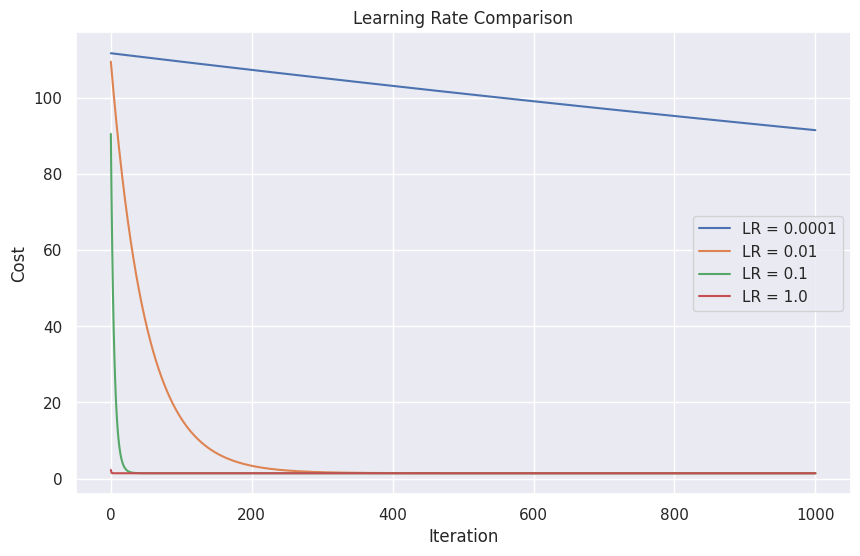

In [47]:
plt.figure(figsize=(10,6))

for lr in learning_rates:

    plt.plot( range(len(cost_history[lr])), cost_history[lr], label=f"LR = {lr}" )

plt.xlabel("Iteration")
plt.ylabel("Cost")

plt.title("Learning Rate Comparison")

plt.legend()
plt.show()

| Learning Rate | Behavior                  | Final Cost Trend   | Result                    |
| ------------- | ------------------------- | ------------------ | ------------------------- |
| 0.0001        | Very slow decrease        | ~91.6              | Slow convergence          |
| 0.01          | Smooth decrease           | ~1.39              | Good convergence          |
| 0.1           | Fast + stable             | ~1.39 (fast reach) | Optimal                 |
| 1.0           | Stops early (gradient ~0) | ~1.39 constant     | Not useful (saturation) |


**Q8. কেন Visualization কঠিন — practically দেখাও** California Housing
dataset এর যেকোনো ২টি feature নাও।

-   matplotlib এর plot_surface দিয়ে ২ feature → target এর 3D regression plane visualize করো

-   এরপর ৩টি feature দিয়ে model train করো এবং same ভাবে visualize করার চেষ্টা করো

-   কোড সহ explain করো ঠিক কোন জায়গায় visualization আর possible না এবং কেন

In [48]:
housing = fetch_california_housing(as_frame=True)

df = housing.frame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


**Q9. Real-world End-to-End Project** Melbourne Housing dataset
([<u>Kaggle</u>](https://www.kaggle.com/datasets/dansbecker/melbourne-housing-snapshot))
নাও।

-   Relevant numeric features বেছে নাও, missing values handle করো

-   Feature ও target এর relationship analyze করো (scatter + correlation)

-   NumPy দিয়ে Gradient Descent চালিয়ে model train করো

-   Sklearn দিয়েও train করো

-   দুটোর MSE compare করো এবং কোনো feature এর coefficient negative হলে real-world এ সেটার meaning explain করো